# Gym Sales Dataset — Exploratory Data Analysis (EDA)

**Dataset:** 12,000 synthetic gym-membership sales conversations, each labelled `SUCCESS` / `FAILURE`.

Each conversation is a two-agent rollout: a salesperson (with a hidden skill level) and a
customer (with hidden objections). The outcome is **emergent** — it is decided by a separate
evaluator model that judges, per objection, whether the salesperson resolved it, and never by
a prompt that was told the answer.

This notebook covers:
1. Load & sanity checks
2. Distributions (persona, skill, gym, price, outcome, length)
3. **The causal signal** — does salesperson skill drive the outcome? (validity check)
4. **Evaluator validation** — Cohen's κ against my own hand-labels
5. **Leakage audit** — can a classifier cheat by reading a style fingerprint?
6. **Model-failure analysis** — instruction-following, hallucinations, over-politeness
7. **Deduplication** — remove exact and near-duplicate conversations
8. Save the cleaned dataset

> Run order matters. Cells build on earlier ones.

## 0. Setup

Install the few libraries the notebook needs (all CPU-only — no GPU required for EDA).

In [14]:
!pip install -q sentence-transformers scikit-learn matplotlib pandas 2>/dev/null
print("libraries ready")

libraries ready


In [35]:
from google.colab import drive
drive.mount('/content/drive')

# Point these at wherever your two final files live.
DATA_PATH = "/content/drive/MyDrive/runi/GSD_IDO/gym_v3_dataset.jsonl"
META_PATH = "/content/drive/MyDrive/runi/GSD_IDO/gym_v3_metadata.jsonl"

import os
for p in (DATA_PATH, META_PATH):
    print(("OK  " if os.path.exists(p) else "MISSING  ") + p)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
OK  /content/drive/MyDrive/runi/GSD_IDO/gym_v3_dataset.jsonl
OK  /content/drive/MyDrive/runi/GSD_IDO/gym_v3_metadata.jsonl


If either file shows **MISSING**, fix the path above. The dataset file is required;
the metadata file is required for the skill-validity and evaluator sections (3, 4). If you
only have the dataset file, sections 1-2 and 5-8 still work.

## 1. Load & sanity checks

We load both files into pandas. `data` is what a model would ever see; `meta` is the latent
state (skill level, which objections resolved) that must **never** become a feature — we use
it only for analysis here.

In [16]:
import json
import pandas as pd

data_rows = [json.loads(l) for l in open(DATA_PATH)]
df = pd.DataFrame(data_rows)

print(f"conversations: {len(df):,}")
print(f"columns      : {list(df.columns)}")
df.head(3)

conversations: 12,000
columns      : ['sample_id', 'outcome', 'dialogue', 'decision_turn_index', 'persona', 'demographic', 'mood', 'gym', 'price', 'n_turns']


,sample_id,outcome,dialogue,decision_turn_index,persona,demographic,mood,gym,price,n_turns
0,0,SUCCESS,"[{'role': 'sales', 'text': 'Hi there! Welcome ...",7,Ariel - Impulsive Commitment-Phobe,"Male, mid-20s - Recently discharged, chasing t...",Defensive about being asked to commit,The Forge Gym,₪179/month,8
1,1,FAILURE,"[{'role': 'sales', 'text': 'Hi there! Welcome ...",7,Ariel - Impulsive Commitment-Phobe,"Male, 30s - Serial hobbyist with a garage full...",Defensive about being asked to commit,The Forge Gym,₪219/month,8
2,2,FAILURE,"[{'role': 'sales', 'text': 'So, you're looking...",7,Yuval - Procrastinating CS Student,"Male, early 20s - Economics student juggling a...","Distracted, mentally still on tomorrow's deadline",Vitality Health Club,₪219/month,8


In [17]:
# metadata (latent state) - joined on sample_id
try:
    meta_rows = [json.loads(l) for l in open(META_PATH)]
    meta = pd.DataFrame(meta_rows).set_index("sample_id")
    HAS_META = True
    print(f"metadata rows: {len(meta):,}")
    print(f"meta columns : {list(meta.columns)}")
except Exception as e:
    HAS_META = False
    print("No metadata loaded - sections 3 & 4 will be skipped.", e)

metadata rows: 12,000
meta columns : ['skill_level', 'hidden_objection_ids', 'hidden_objection_labels', 'objections_resolved_flags', 'objections_resolved_count', 'persuasion_threshold', 'evaluator_reasoning']


In [18]:
# --- structural sanity checks (these mirror the generation-time guarantees) ---
issues = {}

# every turn has exactly {role, text}
issues["stray_keys"] = sum(
    1 for r in data_rows for t in r["dialogue"] if set(t) != {"role", "text"}
)
# roles alternate sales -> customer
issues["bad_alternation"] = sum(
    1 for r in data_rows
    if any(t["role"] != ("sales" if k % 2 == 0 else "customer")
           for k, t in enumerate(r["dialogue"]))
)
# outcome is always one of two values
issues["bad_outcome"] = sum(1 for r in data_rows if r["outcome"] not in ("SUCCESS", "FAILURE"))
# decision_turn_index points at the last turn
issues["bad_decision_idx"] = sum(
    1 for r in data_rows if r["decision_turn_index"] != len(r["dialogue"]) - 1
)
# no duplicate ids
issues["dup_ids"] = len(df) - df["sample_id"].nunique()

print("Structural checks (every value should be 0):")
for k, v in issues.items():
    print(f"  {k:18s}: {v}")

Structural checks (every value should be 0):
  stray_keys        : 0
  bad_alternation   : 0
  bad_outcome       : 0
  bad_decision_idx  : 0
  dup_ids           : 0


## 2. Distributions

First the target, then the design variables. Because the specs were sampled with a
counter-based RNG, the design variables should be close to uniform; the **outcome** is the
one variable we did *not* control — it is emergent, so its balance is informative.

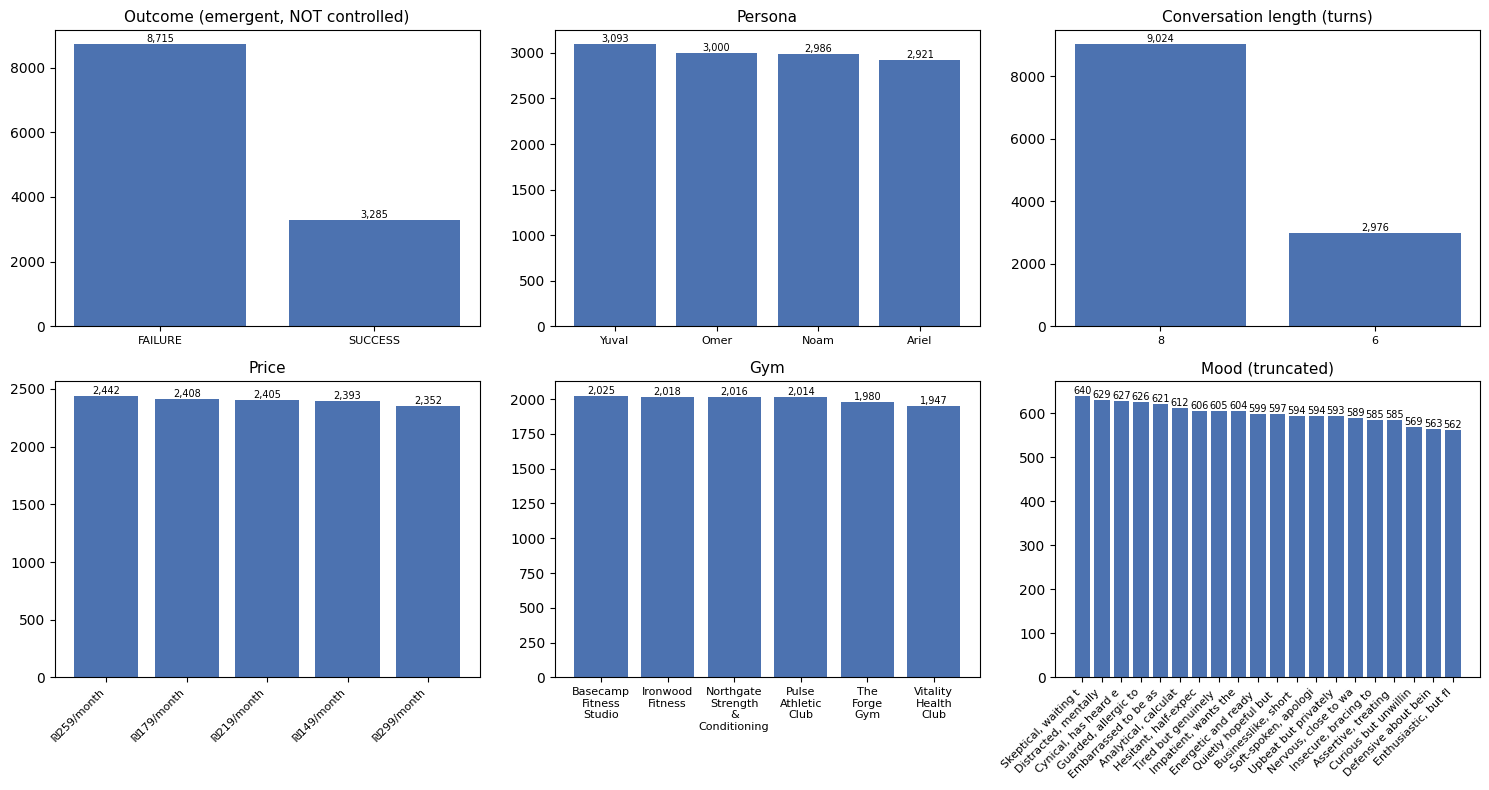

In [19]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

def bar(ax, series, title, rotate=0):
    vc = series.value_counts()
    ax.bar(range(len(vc)), vc.values, color="#4C72B0")
    ax.set_xticks(range(len(vc)))
    ax.set_xticklabels(vc.index, rotation=rotate, ha="right" if rotate else "center", fontsize=8)
    ax.set_title(title, fontsize=11)
    for i, v in enumerate(vc.values):
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=7)

bar(axes[0,0], df["outcome"], "Outcome (emergent, NOT controlled)")
bar(axes[0,1], df["persona"].str.split(" - ").str[0], "Persona")
bar(axes[0,2], df["n_turns"].astype(str), "Conversation length (turns)")
bar(axes[1,0], df["price"], "Price", rotate=45)
bar(axes[1,1], df["gym"].str.replace(" ", "\n"), "Gym", rotate=0)
bar(axes[1,2], df["mood"].str[:20], "Mood (truncated)", rotate=45)

plt.tight_layout()
plt.savefig("dist_overview.png", dpi=110, bbox_inches="tight")
plt.show()

In [20]:
# the numbers behind the target bar
n = len(df)
succ = (df["outcome"] == "SUCCESS").sum()
print(f"SUCCESS : {succ:,} ({100*succ/n:.1f}%)")
print(f"FAILURE : {n-succ:,} ({100*(n-succ)/n:.1f}%)")
print()
print("Class imbalance is EXPECTED and was not forced. Most walk-in sales conversations")
print("do not close. Handle it at training time (class_weight='balanced'), not by resampling here.")

SUCCESS : 3,285 (27.4%)
FAILURE : 8,715 (72.6%)

Class imbalance is EXPECTED and was not forced. Most walk-in sales conversations
do not close. Handle it at training time (class_weight='balanced'), not by resampling here.


**Reading the distributions.** Persona, gym, price and length are near-uniform by design.
The outcome is roughly 1:3 SUCCESS:FAILURE — this was never set by us; it fell out of how
strict the evaluator was and how high the persuasion thresholds were. That it is imbalanced,
not 50/50, is a sign the label is genuinely emergent rather than balanced by construction.

## 3. The causal signal — does skill drive the outcome?

This is the single most important validity check (spec §7.2). The whole dataset is built on
one causal chain:

> **skill_level → salesperson behaviour → objections resolved → outcome**

`skill_level` was sampled **independently** of the customer's difficulty. So if it still
predicts the outcome, that prediction can only run through the salesperson actually resolving
more objections. If the SUCCESS rate were **flat** across skill, the labels would be noise and
the dataset would *look fine while teaching nothing* — the silent failure mode.

The requirement: **SUCCESS must rank novice < average < expert.**

In [21]:
assert HAS_META, "This section needs the metadata file."
import numpy as np

j = df.set_index("sample_id").join(meta)
j["success"] = (j["outcome"] == "SUCCESS").astype(int)

order = ["novice", "average", "expert"]
g = j.groupby("skill_level").agg(
    success_rate=("success", "mean"),
    avg_resolved=("objections_resolved_count", "mean"),
    n=("success", "size"),
).reindex(order)

print(g.to_string(float_format=lambda x: f"{x:.3f}"))

mono = g["success_rate"].is_monotonic_increasing
gap = g.loc["expert","success_rate"] - g.loc["novice","success_rate"]
print(f"\nmonotonic novice<average<expert : {mono}")
print(f"SUCCESS gap (expert - novice)    : {gap:+.3f}")

             success_rate  avg_resolved     n
skill_level                                  
novice              0.228         0.796  3937
average             0.283         0.962  4092
expert              0.309         1.036  3971

monotonic novice<average<expert : True
SUCCESS gap (expert - novice)    : +0.081


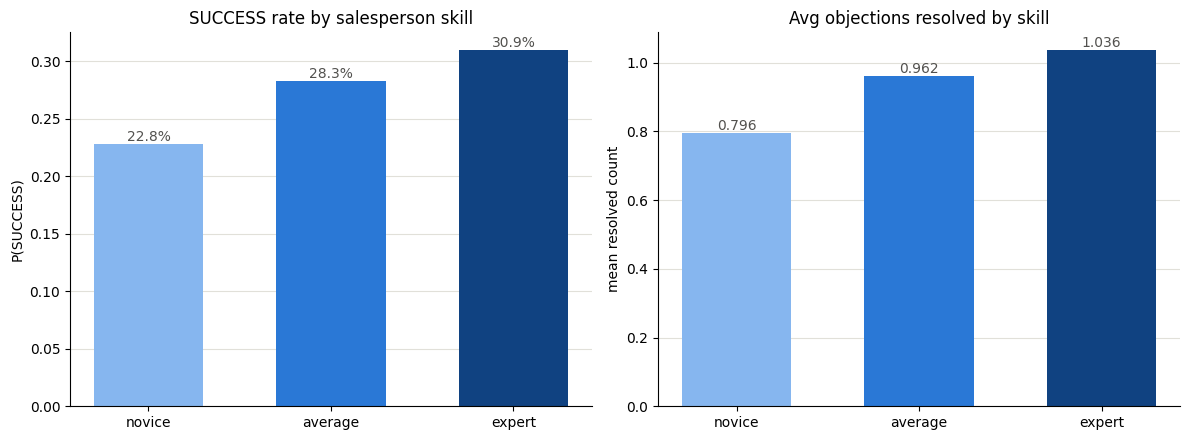

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
RAMP = ["#86b6ef", "#2a78d6", "#104281"]   # blue, light -> dark (novice -> expert)

for a, col, title, ylab in [
    (ax[0], "success_rate", "SUCCESS rate by salesperson skill", "P(SUCCESS)"),
    (ax[1], "avg_resolved", "Avg objections resolved by skill", "mean resolved count"),
]:
    a.bar(order, g[col].values, color=RAMP, width=0.6)
    a.set_title(title)
    a.set_ylabel(ylab)
    fmt = (lambda v: f"{100*v:.1f}%") if col == "success_rate" else (lambda v: f"{v:.3f}")
    for i, v in enumerate(g[col].values):
        a.text(i, v, fmt(v), ha="center", va="bottom", color="#52514e")
    a.grid(axis="y", color="#e1e0d9", lw=0.8)
    a.set_axisbelow(True)
    for s in ("top", "right"):
        a.spines[s].set_visible(False)

plt.tight_layout()
plt.savefig("skill_signal.png", dpi=150, facecolor="#fcfcfb")
plt.show()

**Interpretation.** The SUCCESS rate rises monotonically from novice to expert, and it does
so *because* higher-skill salespeople resolve more objections (right panel). Skill was not
correlated with customer difficulty at sampling time, so this is a genuine causal effect that a
model can learn — a sales coach *should* learn that a rep who deflects tends to lose the sale.

This is emergent, not injected: no prompt was ever told the label. Contrast with a naive
generator told *"write a bad pitch because the label is FAILURE"* — there the seller's words
would encode the answer directly. Here they encode **behaviour**, and the label follows from
whether that behaviour resolved the concerns.

**But keep the magnitude in perspective.** The skill effect is real and monotonic, yet it spans
only 8.1 points (22.8% → 30.9%). Section 4 shows that customer *persona* spans 28.5 points
(15.9% → 44.4%) — roughly 3.5x larger — because personas own objections whose `resolves_when`
criteria differ enormously in how satisfiable they are. Skill is a genuine signal; it is not
the dominant one. Anyone training a classifier on `outcome` should expect persona, not skill,
to carry most of the predictive weight.

## 4. Evaluator validation — Cohen's κ against human labels

The same model family generated the conversations **and** judged them. Self-evaluation bias is
real and, by default, unmeasured. The evaluator is the single point of failure: if its
per-objection judgements are noise, then every `outcome` is noise and every number above is
meaningless.

So we validate it against a human: **you**. The cell below shows you N conversations, one hidden
objection at a time, and asks you to judge — blind to the evaluator's verdict — whether the
salesperson resolved it. Then we compute Cohen's κ between your labels and the evaluator's.

| κ | verdict |
|---|---|
| > 0.6 | trustworthy |
| 0.4–0.6 | moderate — usable, report it |
| < 0.4 | labels are noise — stop and fix |

> This takes ~20–30 minutes of your attention. It is the difference between *"I trained a model
> and got 87%"* and *"the evaluator was validated against human annotation, κ = 0.7."*

In [23]:
# Pick a reproducible random sample of conversations to hand-label.
import random
random.seed(7)

N_LABEL = 20   # 20 conversations -> ~45-50 objection judgements
sample_ids = random.sample(list(df["sample_id"]), N_LABEL)

# Build the list of (sample_id, objection_index) to judge, with the evaluator's hidden verdict.
tasks = []
for sid in sample_ids:
    mrow = meta.loc[sid]
    for k, obj in enumerate(mrow["hidden_objection_labels"]):
        tasks.append({
            "sample_id": sid,
            "obj_index": k,
            "objection": obj,
            "eval_verdict": int(mrow["objections_resolved_flags"][k]),  # hidden from you
        })
print(f"{len(tasks)} objection-judgements to label across {N_LABEL} conversations.")

46 objection-judgements to label across 20 conversations.


In [41]:
# Run this cell to label interactively. For each objection you type 1 (resolved) or 0 (not).
# You do NOT see the evaluator's verdict while labelling.
data_by_id = {r["sample_id"]: r for r in data_rows}

human_labels = []
for i, t in enumerate(tasks):
    conv = data_by_id[t["sample_id"]]
    print("=" * 78)
    print(f"Judgement {i+1}/{len(tasks)}  (conversation {t['sample_id']})")
    print("-" * 78)
    for turn in conv["dialogue"][:conv["decision_turn_index"]]:   # hide the decision turn
        who = "ADVISOR " if turn["role"] == "sales" else "CUSTOMER"
        print(f"{who}: {turn['text']}")
    print("-" * 78)
    print(f"OBJECTION: {t['objection']}")
    ans = input("Did the ADVISOR resolve it concretely?  1 = yes, 0 = no  > ").strip()
    human_labels.append(1 if ans == "1" else 0)

print("\nDone. Now run the next cell to compute kappa.")

Judgement 1/46  (conversation 5305)
------------------------------------------------------------------------------
ADVISOR : Hi there! Welcome to Basecamp Fitness Studio. I'd love to help you join. How long do you plan to stay active each week?
CUSTOMER: Thanks for walking me through the options. And let me be honest, that getting there and back adds up to almost two hours each session – with work and exams already consuming most of my free time.
ADVISOR : I understand, we get that balance is key. Our free intro session with a trainer can help tailor workouts for your schedule, maybe even some shorter sessions like the Express Option?
CUSTOMER: That sounds helpful. But you see, my actual concern is that my chaotic schedule with exams and assignments means I won't stick to any routine, no matter how tempting these options might seem.
ADVISOR : Got it. Sometimes life gets hectic, but we do offer flexible options like Pay As You Go or single entries. We can also suggest some shorter sessi

In [25]:
from sklearn.metrics import cohen_kappa_score, confusion_matrix

human = human_labels
model = [t["eval_verdict"] for t in tasks]

kappa = cohen_kappa_score(human, model)
agree = sum(h == m for h, m in zip(human, model)) / len(human)

print(f"n judgements     : {len(human)}")
print(f"raw agreement    : {100*agree:.1f}%")
print(f"Cohen's kappa    : {kappa:.3f}")
print()
cm = confusion_matrix(human, model, labels=[1,0])
print("confusion (rows=human, cols=evaluator)   [resolved, not]")
print(cm)
print()
verdict = ("TRUSTWORTHY" if kappa > 0.6 else
           "MODERATE - usable, report it" if kappa >= 0.4 else
           "NOISE - fix resolves_when before trusting labels")
print(f"VERDICT: kappa={kappa:.2f} -> {verdict}")

n judgements     : 46
raw agreement    : 67.4%
Cohen's kappa    : 0.218

confusion (rows=human, cols=evaluator)   [resolved, not]
[[ 6  9]
 [ 6 25]]

VERDICT: kappa=0.22 -> NOISE - fix resolves_when before trusting labels


**Where the disagreement lives.** A κ of 0.218 says the evaluator and I read the criteria
differently, but not *which* criteria. Since the metadata records a per-objection verdict for
all 12,000 conversations, we can ask that directly: for each of the 16 objection types, how
often did the evaluator judge it resolved? The objections at the bottom of this chart are the
ones whose `resolves_when` wording is doing the least work — and they are where a v4 of this
dataset should start.

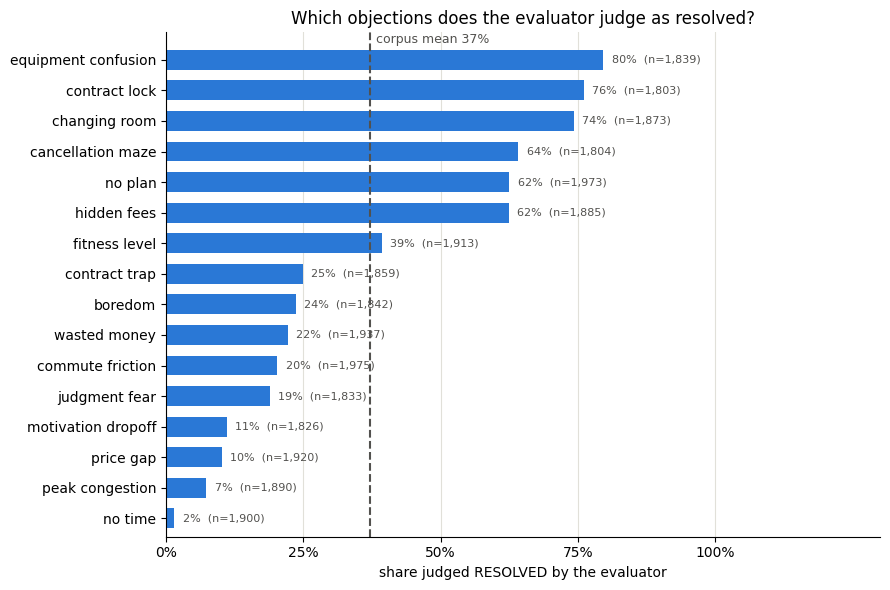

In [37]:
from collections import defaultdict

obj_stats = defaultdict(lambda: [0, 0])          # objection_id -> [resolved, total]
for m in meta_rows:
    for oid, flag in zip(m["hidden_objection_ids"], m["objections_resolved_flags"]):
        obj_stats[oid][0] += int(flag)
        obj_stats[oid][1] += 1

rows   = sorted(((k, v[0] / v[1], v[1]) for k, v in obj_stats.items()), key=lambda r: r[1])
names  = [r[0].replace("_", " ") for r in rows]
rates  = [r[1] for r in rows]
counts = [r[2] for r in rows]
corpus = sum(v[0] for v in obj_stats.values()) / sum(v[1] for v in obj_stats.values())

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(names, rates, color="#2a78d6", height=0.65)
ax.axvline(corpus, color="#52514e", ls="--", lw=1.5)

for i, (r, n) in enumerate(zip(rates, counts)):
    ax.text(r + 0.015, i, f"{100*r:.0f}%  (n={n:,})", va="center", color="#52514e", fontsize=8)

ax.set_xlim(0, 1.3)
ax.set_xticks([0, 0.25, 0.5, 0.75, 1.0])
ax.set_xticklabels(["0%", "25%", "50%", "75%", "100%"])
ax.set_ylim(-0.6, len(names) - 0.1)
ax.text(corpus + 0.01, len(names) - 0.35, f"corpus mean {100*corpus:.0f}%",
        color="#52514e", fontsize=9, va="center")

ax.set_xlabel("share judged RESOLVED by the evaluator")
ax.set_title("Which objections does the evaluator judge as resolved?")
ax.grid(axis="x", color="#e1e0d9", lw=0.8)
ax.set_axisbelow(True)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)

plt.tight_layout()
plt.savefig("objection_difficulty.png", dpi=150, facecolor="#fcfcfb")
plt.show()

**How objection difficulty propagates to personas.** Objections are owned by personas — each
persona draws 2-3 from its own pool of 4. So if some criteria are near-unsatisfiable and others
near-automatic, a customer's persona partly determines the outcome before the salesperson says
a word. The two panels below test that: the left is the observed SUCCESS rate per persona, the
right is the average share of that persona's objections the evaluator judged resolved. If the
two panels rank the personas the same way, the outcome is being driven by the hand each
customer was dealt, not only by how well the advisor played it.

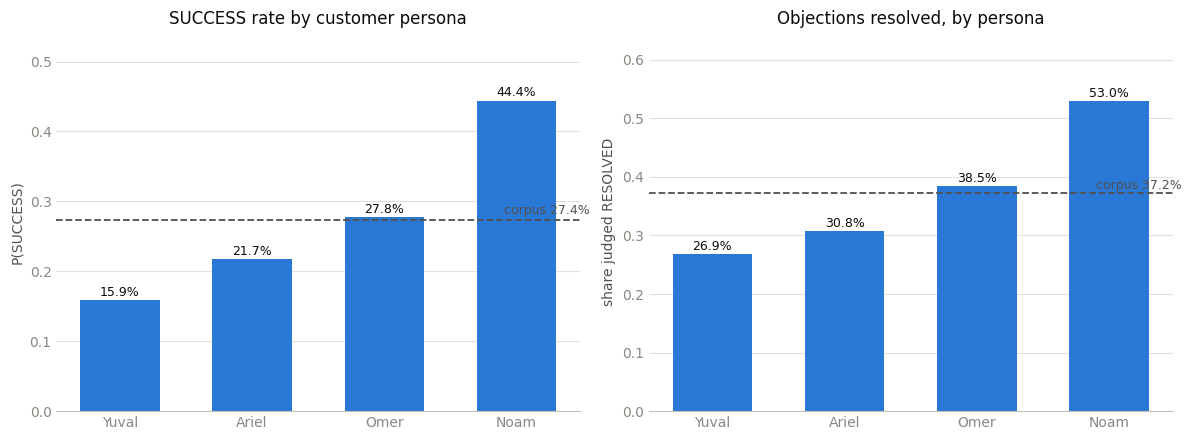

In [42]:
from collections import defaultdict

persona_by_id = df.set_index("sample_id")["persona"].to_dict()

# panel 1 - observed SUCCESS rate per persona
ps = (df.assign(success=(df["outcome"] == "SUCCESS").astype(int))
        .groupby("persona")["success"].agg(["mean", "size"]))

# panel 2 - share of that persona's objections judged resolved
pr = defaultdict(lambda: [0, 0])
for m in meta_rows:
    p = persona_by_id[m["sample_id"]]
    pr[p][0] += sum(int(f) for f in m["objections_resolved_flags"])
    pr[p][1] += len(m["objections_resolved_flags"])
obj_rate = {p: v[0] / v[1] for p, v in pr.items()}

order_p = ps["mean"].sort_values().index
short   = [p.split(" - ")[0] for p in order_p]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

panels = [
    (ax[0], [ps.loc[p, "mean"] for p in order_p], (df["outcome"] == "SUCCESS").mean(),
     "SUCCESS rate by customer persona", "P(SUCCESS)"),
    (ax[1], [obj_rate[p] for p in order_p],
     sum(v[0] for v in pr.values()) / sum(v[1] for v in pr.values()),
     "Objections resolved, by persona", "share judged RESOLVED"),
]

for a, vals, ref, title, ylab in panels:
    a.bar(short, vals, color="#2a78d6", width=0.6)
    a.axhline(ref, color="#52514e", ls="--", lw=1.3)
    a.text(len(short) - 0.45, ref + 0.008, f"corpus {100*ref:.1f}%",
           color="#52514e", fontsize=9, ha="right")
    for i, v in enumerate(vals):
        a.text(i, v + 0.006, f"{100*v:.1f}%", ha="center", color="#0b0b0b", fontsize=9)
    a.set_title(title, color="#0b0b0b")
    a.set_ylabel(ylab, color="#52514e")
    a.set_ylim(0, max(vals) * 1.22)
    a.grid(axis="y", color="#e1e0d9", lw=0.8)
    a.set_axisbelow(True)
    a.tick_params(colors="#898781", length=0)
    for s in ("top", "right", "left"):
        a.spines[s].set_visible(False)
    a.spines["bottom"].set_color("#c3c2b7")

plt.tight_layout()
plt.savefig("persona_signal.png", dpi=150, facecolor="#fcfcfb")
plt.show()

**Record the number.** Whatever κ you get, state it honestly in the dataset card and in the
presentation. A moderate κ is still a real, measured result and far stronger than no validation
at all. If κ comes back below 0.4, that is a genuine finding — the `resolves_when` criteria are
too vague — and it would mean the labels need work before the dataset is used.

## 5. Leakage audit — can a classifier cheat?

A subtle failure: if the salesperson's *style* encodes the outcome, a classifier can predict
the label from the seller's early turns **before the customer has decided anything**. That
information cannot exist in real data — it would mean we accidentally wrote the answer into the
text (the way an earlier version of this dataset did, scoring 90% here).

The test (spec §7.1): train TF-IDF + Logistic Regression on **only the salesperson's turns,
excluding the final pitch**, and see how well it predicts the outcome.

| accuracy | meaning |
|---|---|
| 55–65% | healthy — emergent dynamics, no leakage |
| 65–70% | borderline — usable, report honestly |
| > 70% | leakage — the model reads a style fingerprint, not substance |

We **stratify by n_turns**, because pooling 6- and 8-turn conversations lets the classifier use
length as a proxy, which inflates the number.

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
import numpy as np

def sales_turns_excluding_final_pitch(row):
    # salesperson turns are at even indices; the final pitch is the last sales turn
    sales = [t["text"] for i, t in enumerate(row["dialogue"])
             if t["role"] == "sales"]
    return " ".join(sales[:-1]) if len(sales) > 1 else ""

y = np.array([r["outcome"] == "SUCCESS" for r in data_rows])
X_text = [sales_turns_excluding_final_pitch(r) for r in data_rows]
n_turns = np.array([r["n_turns"] for r in data_rows])

probe_results = []          # keep the numbers so the chart below cannot go stale

def probe(mask, label):
    Xt = [x for x, m in zip(X_text, mask) if m and x]
    yt = [yy for yy, m, x in zip(y, mask, X_text) if m and x]
    if len(set(yt)) < 2:
        print(f"  {label}: skipped"); return
    pipe = make_pipeline(
        TfidfVectorizer(ngram_range=(1,2), min_df=3, max_features=20000),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    )
    scores = cross_val_score(pipe, Xt, yt, cv=5, scoring="accuracy")
    base = max(np.mean(yt), 1 - np.mean(yt))
    probe_results.append({"label": label, "acc": scores.mean(),
                          "std": scores.std(), "baseline": base, "n": len(yt)})
    print(f"  {label:22s}: acc={scores.mean():.3f} (+/-{scores.std():.3f})  baseline={base:.3f}  n={len(yt)}")

print("Leakage probe — salesperson turns, excluding final pitch:\n")
probe(n_turns == 6, "6-turn conversations")
probe(n_turns == 8, "8-turn conversations")
print("\n55-65% = healthy | 65-70% = borderline | >70% = leakage")

Leakage probe — salesperson turns, excluding final pitch:

  6-turn conversations  : acc=0.642 (+/-0.011)  baseline=0.634  n=2976
  8-turn conversations  : acc=0.694 (+/-0.005)  baseline=0.757  n=9024

55-65% = healthy | 65-70% = borderline | >70% = leakage


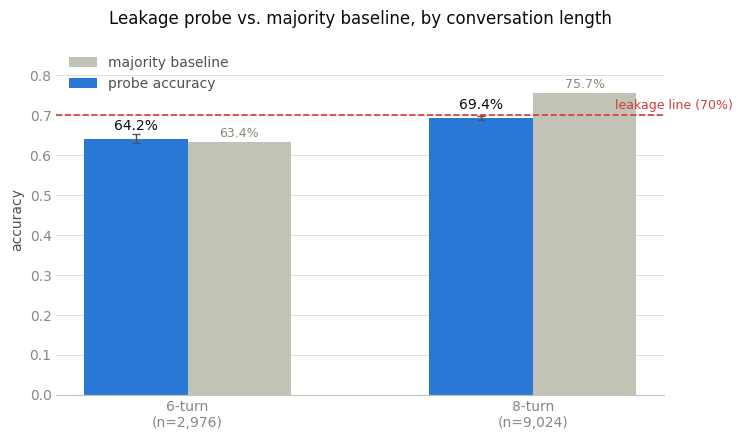

In [40]:
labels   = [f"{r['label'].split()[0]}\n(n={r['n']:,})" for r in probe_results]
acc      = [r["acc"] for r in probe_results]
err      = [r["std"] for r in probe_results]
baseline = [r["baseline"] for r in probe_results]

x = np.arange(len(labels)); w = 0.30
fig, ax = plt.subplots(figsize=(7.5, 4.5))

ax.bar(x + w/2, baseline, w, label="majority baseline", color="#c3c2b7")
ax.bar(x - w/2, acc, w, yerr=err, capsize=3, label="probe accuracy",
       color="#2a78d6", error_kw={"ecolor": "#52514e", "lw": 1})

ax.axhline(0.70, color="#d03b3b", ls="--", lw=1.2)
ax.text(len(labels) - 0.42, 0.715, "leakage line (70%)",
        color="#d03b3b", fontsize=9, ha="right")

for xi, (a, b) in enumerate(zip(acc, baseline)):
    ax.text(xi - w/2, a + 0.022, f"{100*a:.1f}%", ha="center",
            color="#0b0b0b", fontsize=10, fontweight="medium")
    ax.text(xi + w/2, b + 0.012, f"{100*b:.1f}%", ha="center",
            color="#898781", fontsize=9)

ax.set_xticks(x); ax.set_xticklabels(labels, color="#52514e")
ax.set_ylim(0, 0.88); ax.set_ylabel("accuracy", color="#52514e")
ax.set_title("Leakage probe vs. majority baseline, by conversation length",
             color="#0b0b0b", pad=14)
ax.legend(frameon=False, loc="upper left", labelcolor="#52514e")
ax.grid(axis="y", color="#e1e0d9", lw=0.8); ax.set_axisbelow(True)
ax.tick_params(colors="#898781", length=0)
for s in ("top", "right", "left"):
    ax.spines[s].set_visible(False)
ax.spines["bottom"].set_color("#c3c2b7")

plt.tight_layout()
plt.savefig("leakage_audit.png", dpi=150, facecolor="#fcfcfb")
plt.show()

**Interpretation.** Read the accuracy against the baseline (always-predict-majority). The two
strata land differently, and we report both readings rather than picking the flattering one:

- **6-turn - 64.2% vs a 63.4% baseline.** Inside the healthy band and essentially at baseline.
- **8-turn - 69.4% vs a 75.7% baseline.** Inside the *borderline* band by raw accuracy, yet
  **below** its own baseline - the probe does not actually beat guessing the majority class.

Neither stratum approaches the >70% leakage line. An earlier version of this dataset scored
90% here, so the `SKILL_LEVELS` rewrite - behaviour, not style - did its job. If a future run
climbed above 70%, the fix would be there again: make the three skill descriptions less
caricatured.

## 6. Model-failure analysis

The assignment explicitly asks us to *identify and flag* the ways the generator misbehaves.
These are not fatal — they are documented limitations. We quantify four:

- **objection voicing** — did the customer actually raise his hidden objections?
- **over-politeness** — the customer was told to be businesslike, not to thank the advisor
- **fact hallucination** — did the salesperson invent terms that contradict the fact sheet?
- **price consistency** — does the advisor quote the membership price he was given?

In [27]:
import re

# 6a. over-politeness in customer turns
NICE = re.compile(r"(that sounds (good|great|perfect)|sounds (good|great|perfect)|"
                  r"thank you for (the|explaining|all)|thanks for (the|all|explaining)|"
                  r"i appreciate (the|you|all)|that clears things up)", re.I)

nice_turns = nice_total = 0
for r in data_rows:
    for t in r["dialogue"][:r["decision_turn_index"]]:
        if t["role"] == "customer":
            nice_total += 1
            if NICE.search(t["text"]):
                nice_turns += 1
print(f"over-politeness : {nice_turns}/{nice_total} customer turns = {100*nice_turns/nice_total:.1f}%")

# 6b. fact hallucination in sales turns (fee/penalty invented, ignoring negated mentions)
HALLU = re.compile(r"(cancellation|freeze|termination)\s+fee|\b(penalty|penalties)\b|\bdeposit\b", re.I)
NEG = re.compile(r"\b(no|not|never|without|zero|free of)\b[^.!?]{0,40}$", re.I)
hallu = sales = 0
for r in data_rows:
    for t in r["dialogue"]:
        if t["role"] == "sales":
            sales += 1
            m = HALLU.search(t["text"])
            if m and not NEG.search(t["text"][max(0,m.start()-45):m.start()]):
                hallu += 1
print(f"fact hallucination: {hallu}/{sales} sales turns = {100*hallu/sales:.2f}%")

over-politeness : 6637/33024 customer turns = 20.1%
fact hallucination: 294/45024 sales turns = 0.65%


In [28]:
# 6c. objection voicing - needs metadata + the keyword map from personas.py
if HAS_META:
    # inline a compact keyword map (same spirit as personas.OBJECTION_KEYWORDS)
    KW = {
     "no_time":["time","schedule","busy","exam","hours","fit it in","show up"],
     "wasted_money":["waste","not use","never use","subscription","money","unused"],
     "no_plan":["what to do","would not know","plan","lost","structure","guidance"],
     "commute_friction":["get there","travel","commute","far","each way","back and forth","distance"],
     "price_gap":["cheaper","competitor","other gym","less expensive","price","cost","elsewhere"],
     "hidden_fees":["hidden","registration","joining fee","card fee","locker fee","real price","fee"],
     "contract_lock":["locked","year","12-month","renew","renewal","committed","tied"],
     "peak_congestion":["crowded","wait","queue","squat rack","packed","peak","equipment"],
     "contract_trap":["contract","locked","quit","trapped","stuck","commit","tied"],
     "cancellation_maze":["cancel","cancellation","quit","get out","leave","terminate"],
     "boredom":["bored","boring","same routine","repetitive","variety","monotony","lose interest"],
     "motivation_dropoff":["motivation","keep going","stick with","give up","wears off","accountab"],
     "judgment_fear":["judge","look at me","fit people","belong","intimidat","embarrass","stare"],
     "equipment_confusion":["machine","equipment","how to use","look stupid","operate"],
     "fitness_level":["out of shape","unfit","too old","not last","shape","beginner","keep up"],
     "changing_room":["changing","shower","locker room","private","undress","cubicle"],
    }
    voiced = miss = 0
    per_obj = {}
    for r in data_rows:
        mrow = meta.loc[r["sample_id"]]
        ctext = " ".join(t["text"] for t in r["dialogue"] if t["role"]=="customer").lower()
        for oid in mrow["hidden_objection_ids"]:
            hit = any(k in ctext for k in KW.get(oid, []))
            voiced += hit; miss += (not hit)
            per_obj.setdefault(oid, [0,0])[0 if hit else 1] += 1
    print(f"objection voicing: {voiced}/{voiced+miss} = {100*voiced/(voiced+miss):.1f}%")
    print("\n(keyword-matching is a floor; true voicing is higher - some objections are")
    print(" phrased indirectly and missed by keywords.)")

objection voicing: 23982/30072 = 79.7%

(keyword-matching is a floor; true voicing is higher - some objections are
 phrased indirectly and missed by keywords.)


**6d. Price consistency.** The advisor's system prompt states the sampled membership price.
Does he actually quote it, and does he quote it correctly? This matters because anything
downstream that displays the `price` field alongside the transcript will look broken if the
two disagree.


In [45]:
MEMBERSHIP = {"149", "179", "219", "259", "299"}

true_mismatch, stated_ok, never_stated = 0, 0, 0
bad = []

for r in data_rows:
    spec = re.search(r"\d+", r["price"]).group()
    sales_text = " ".join(t["text"] for t in r["dialogue"] if t["role"] == "sales")
    found = {a for a in re.findall(r"[₪$]\s?(\d{2,4})", sales_text)} & MEMBERSHIP

    if not found:
        never_stated += 1
    elif found == {spec}:
        stated_ok += 1
    else:
        true_mismatch += 1
        if len(bad) < 5:
            bad.append((r["sample_id"], spec, sorted(found)))

n = len(data_rows)
print(f"membership price stated correctly : {stated_ok:,}/{n:,} = {100*stated_ok/n:.1f}%")
print(f"membership price never stated     : {never_stated:,}/{n:,} = {100*never_stated/n:.1f}%")
print(f"CONTRADICTS the spec price        : {true_mismatch:,}/{n:,} = {100*true_mismatch/n:.1f}%")
print()
for sid, spec, found in bad:
    print(f"  [{sid}] spec ₪{spec}, dialogue states ₪{found}")

membership price stated correctly : 2,733/12,000 = 22.8%
membership price never stated     : 9,258/12,000 = 77.2%
CONTRADICTS the spec price        : 9/12,000 = 0.1%

  [657] spec ₪299, dialogue states ₪['259', '299']
  [1612] spec ₪299, dialogue states ₪['259']
  [2445] spec ₪299, dialogue states ₪['259', '299']
  [2625] spec ₪179, dialogue states ₪['179', '219']
  [3545] spec ₪259, dialogue states ₪['219', '259']


**These are documented limitations, not bugs to chase.** Over-politeness is cosmetic — the
evaluator judges the *salesperson's answer* against the criterion, not the customer's manners.
Hallucination is very low. Objection voicing measured by keywords is a floor, because indirect
phrasings slip past the word list. All three belong in the dataset card's *Known Limitations*
section, stated honestly.

## 7. Deduplication

Two conversations that are identical or near-identical would leak across a train/test split and
inflate every downstream metric. We remove:

1. **Exact duplicates** — identical dialogue text.
2. **Near-duplicates** — cosine similarity above a threshold in sentence-embedding space.

We generated 12,000 with a buffer precisely so that after this step we remain safely above the
required 10,000.

In [29]:
# 7a. exact duplicates on the full dialogue text
def dialogue_text(r):
    return "\n".join(t["text"] for t in r["dialogue"])

seen = {}
exact_dupe_ids = set()
for r in data_rows:
    key = dialogue_text(r)
    if key in seen:
        exact_dupe_ids.add(r["sample_id"])
    else:
        seen[key] = r["sample_id"]
print(f"exact duplicates: {len(exact_dupe_ids)}")

exact duplicates: 0


In [30]:
# 7b. near-duplicates via sentence embeddings (excluding the decision turn,
#     so we compare the *conversation*, not the closing line)
from sentence_transformers import SentenceTransformer
import numpy as np

embedder = SentenceTransformer("all-MiniLM-L6-v2")   # small, fast, CPU-ok

def body_text(r):
    return " ".join(t["text"] for t in r["dialogue"][:r["decision_turn_index"]])

kept = [r for r in data_rows if r["sample_id"] not in exact_dupe_ids]
texts = [body_text(r) for r in kept]

print(f"embedding {len(texts):,} conversations ...")
emb = embedder.encode(texts, batch_size=128, show_progress_bar=True,
                      convert_to_numpy=True, normalize_embeddings=True)
print("done:", emb.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

embedding 12,000 conversations ...


Batches:   0%|          | 0/94 [00:00<?, ?it/s]

done: (12000, 384)


In [31]:
# 7c. greedy near-duplicate removal with a similarity threshold.
# Uses a blocked matrix-multiply so it scales to 12k without a 12k x 12k matrix in RAM.
THRESHOLD = 0.95   # cosine; 0.95 = near-identical. Raise toward 0.97 to remove fewer.

import numpy as np
n = len(emb)
remove = np.zeros(n, dtype=bool)
block = 512
for i in range(0, n, block):
    if remove[i:i+block].all():
        continue
    sims = emb[i:i+block] @ emb.T          # (block, n)
    for bi in range(sims.shape[0]):
        gi = i + bi
        if remove[gi]:
            continue
        dup = np.where(sims[bi] > THRESHOLD)[0]
        dup = dup[dup > gi]                 # only remove later items
        remove[dup] = True

near_dupe_ids = {kept[i]["sample_id"] for i in range(n) if remove[i]}
print(f"near-duplicates (threshold {THRESHOLD}): {len(near_dupe_ids)}")

near-duplicates (threshold 0.95): 3


In [32]:
# 7d. final cleaned set
drop_ids = exact_dupe_ids | near_dupe_ids
clean_rows = [r for r in data_rows if r["sample_id"] not in drop_ids]

print(f"original          : {len(data_rows):,}")
print(f"exact dupes       : -{len(exact_dupe_ids):,}")
print(f"near dupes        : -{len(near_dupe_ids):,}")
print(f"CLEANED total     : {len(clean_rows):,}")
assert len(clean_rows) >= 10000, "Dropped below 10k - raise THRESHOLD and re-run 7c/7d."
print("\nStill above the 10,000 requirement." )

# outcome balance after dedup (should barely move)
cs = sum(1 for r in clean_rows if r["outcome"]=="SUCCESS")
print(f"SUCCESS after dedup: {cs:,} ({100*cs/len(clean_rows):.1f}%)")

original          : 12,000
exact dupes       : -0
near dupes        : -3
CLEANED total     : 11,997

Still above the 10,000 requirement.
SUCCESS after dedup: 3,285 (27.4%)


## 8. Save the cleaned dataset

Write the deduplicated dataset back out. This cleaned file is what we upload to Hugging Face
and what the recommender and application will read.

In [34]:
OUT = "/content/drive/MyDrive/runi/GSD_IDO/gym_v3_dataset_clean.jsonl"
with open(OUT, "w") as f:
    for r in clean_rows:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

print(f"wrote {len(clean_rows):,} rows to:\n{OUT}")
print("\nEDA complete. Summary for the dataset card:")
print(f"  - conversations (clean) : {len(clean_rows):,}")
print(f"  - SUCCESS rate          : {100*cs/len(clean_rows):.1f}%")
print("  - skill signal          : monotonic novice<average<expert (section 3)")
print("  - evaluator kappa       : 0.218 over 46 judgements (67.4% raw agreement)")
print("  - leakage probe         : 6-turn 64.2% (base 63.4%) | 8-turn 69.4% (base 75.7%)")

wrote 11,997 rows to:
/content/drive/MyDrive/runi/GSD_IDO/gym_v3_dataset_clean.jsonl

EDA complete. Summary for the dataset card:
  - conversations (clean) : 11,997
  - SUCCESS rate          : 27.4%
  - skill signal          : monotonic novice<average<expert (section 3)
  - evaluator kappa       : 0.218 over 46 judgements (67.4% raw agreement)
  - leakage probe         : 6-turn 64.2% (base 63.4%) | 8-turn 69.4% (base 75.7%)


---

### What goes in the Hugging Face dataset card (README)

Paste the key numbers from this notebook:
- Size, class balance, and how the label is defined
- **Section 3** — the skill→outcome signal (the validity result)
- **Section 4** — Cohen's κ (the evaluator-trust result)
- **Section 5** — the leakage-probe accuracy (the no-cheating result)
- **Section 6** — the three limitations, stated honestly
- **Section 7** — how many duplicates were removed

That combination — a validity check, an evaluator-trust number, a leakage number, and honest
limitations — is exactly what a strong dataset card looks like.